In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import RandomOverSampler

#importing libraries

In [5]:
df = pd.read_csv("WineQT.csv")
df.head()

#loading data set

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [7]:
print("Shape:", df.shape)
df.info()
df.describe()
df.columns

#understanding data

Shape: (1143, 13)
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='str')

In [8]:
df.isnull().sum()

#checking for nulls , and there is non

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [10]:
df.duplicated().sum()
df.shape

#cheching for duplicates , there in non too

(1143, 13)

In [11]:
# seeing how "Quality" classes are distributed
df["quality"].value_counts().sort_index()


quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

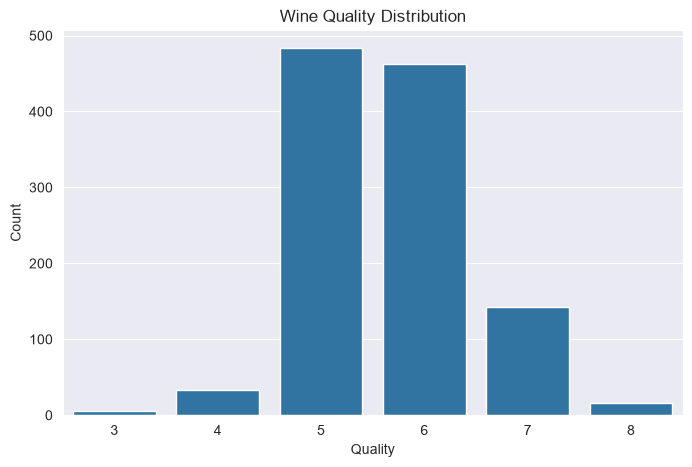

In [12]:
#Visualization
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="quality")

plt.title("Wine Quality Distribution")
plt.xlabel("Quality")
plt.ylabel("Count")
plt.show()

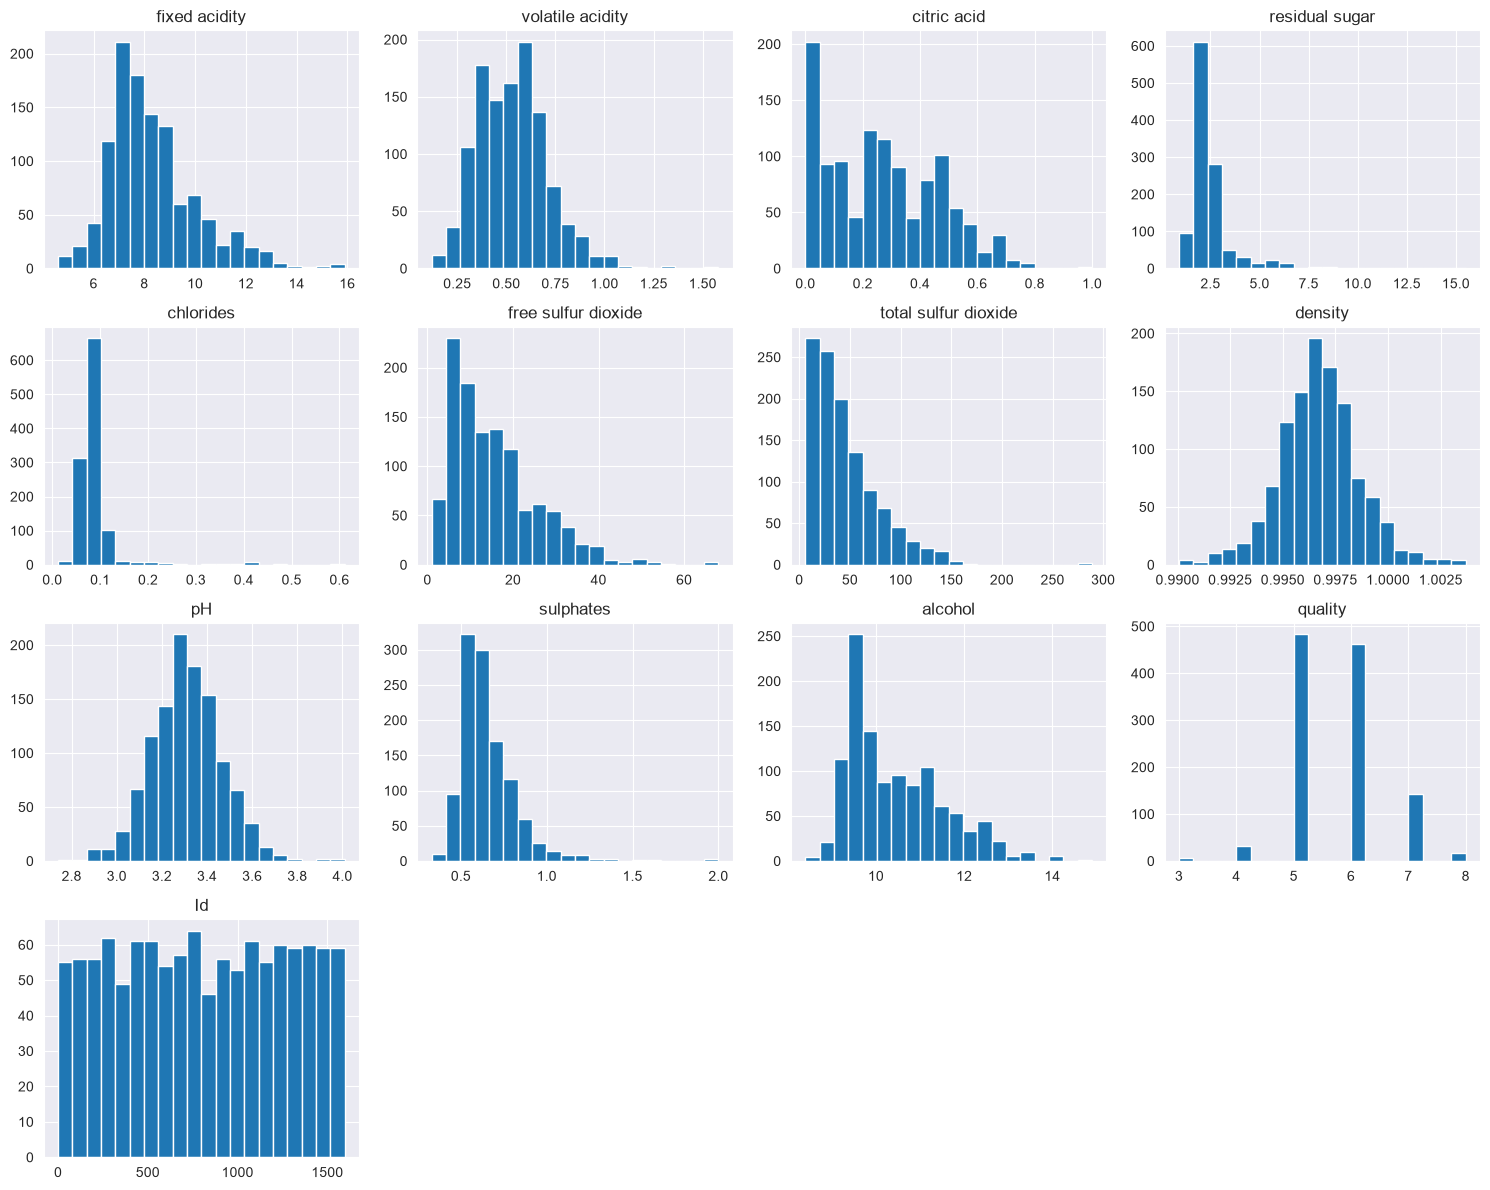

In [13]:
#Feature Distributions for numerical data
df.hist(
    figsize=(15,12),
    bins=20
)

plt.tight_layout()
plt.show()

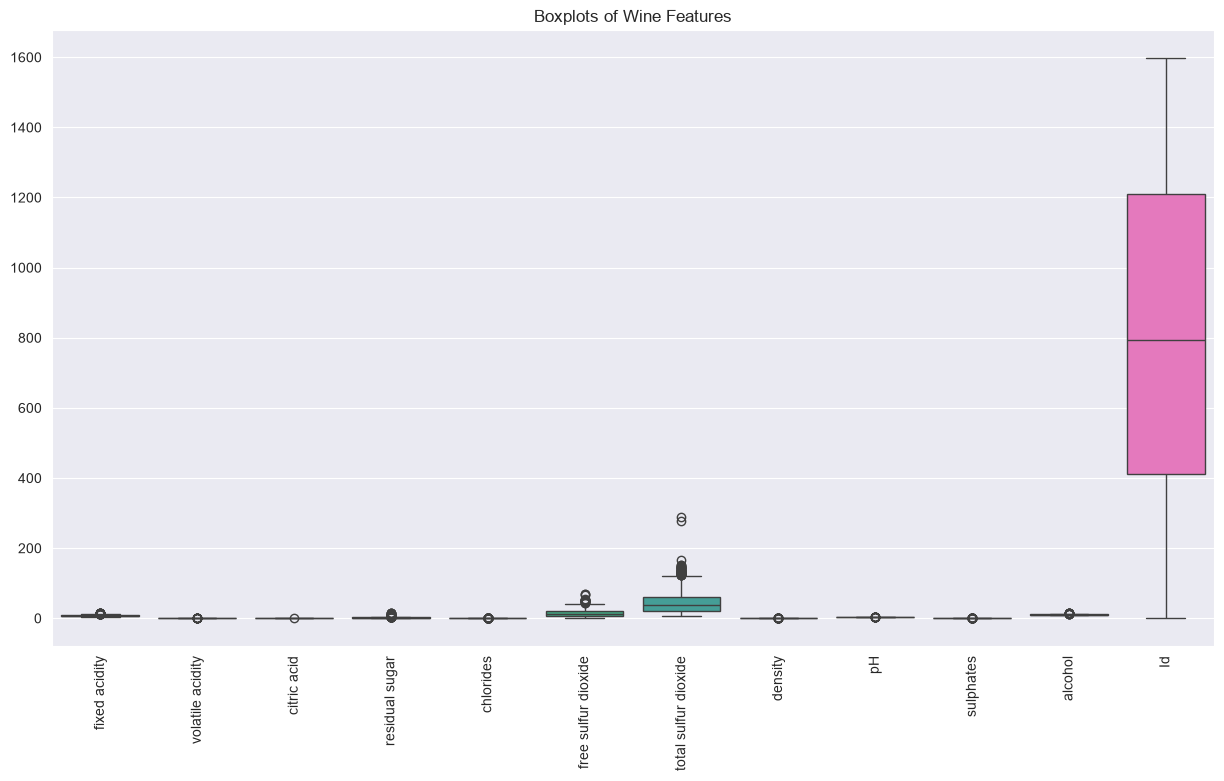

In [14]:
#box plot to see outliers
plt.figure(figsize=(15,8))
sns.boxplot(data=df.drop(columns=["quality"]))

plt.xticks(rotation=90)
plt.title("Boxplots of Wine Features")
plt.show()

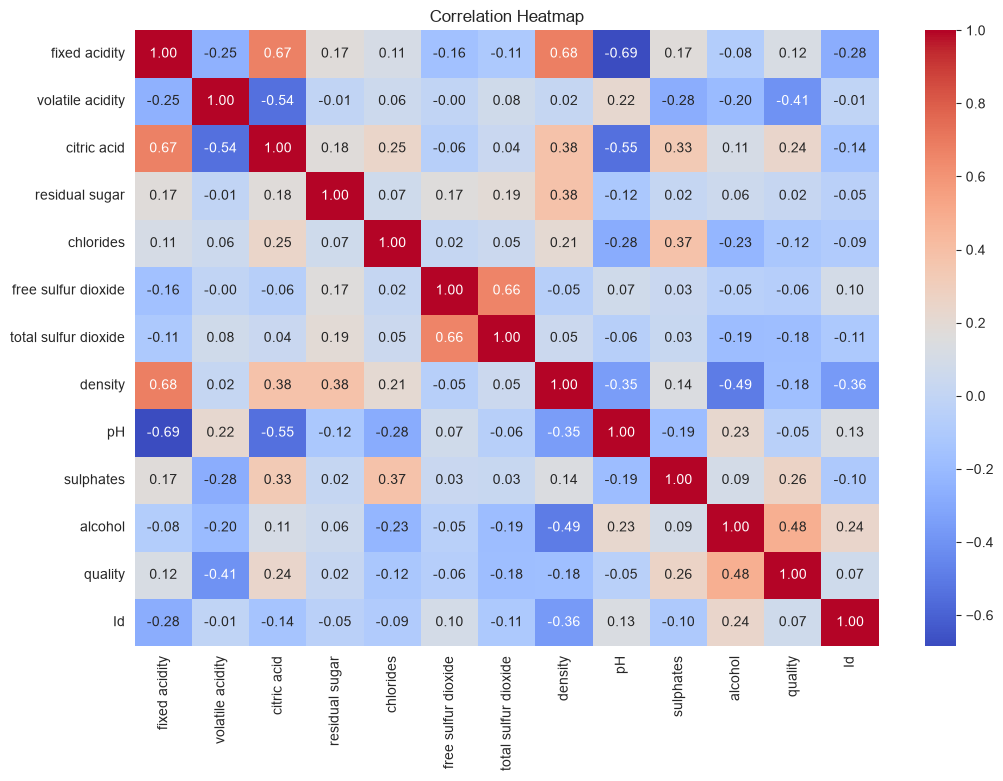

In [15]:
#Correlation Heatmap to see relationships between features
plt.figure(figsize=(12,8))

corr = df.corr(numeric_only=True)
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

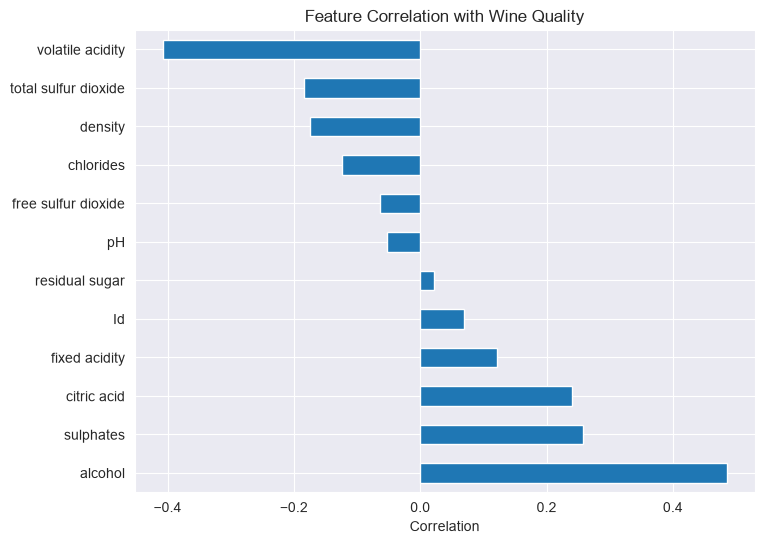

In [17]:
#relationship between quality and other features
quality_corr = (
    df.corr(numeric_only=True)["quality"]
    .sort_values(ascending=False)
)



plt.figure(figsize=(8,6))

quality_corr.drop("quality").plot(kind="barh")

plt.title("Feature Correlation with Wine Quality")
plt.xlabel("Correlation")
plt.show()

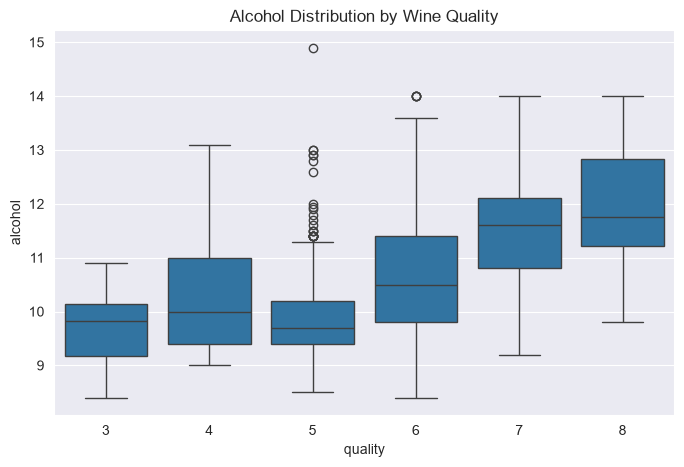

In [18]:
#scatter plot between quality and alcohol
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="quality",
    y="alcohol"
)

plt.title("Alcohol Distribution by Wine Quality")
plt.show()

In [21]:
#X and Y
X = df.drop(columns=["quality", "Id"])
y = df["quality"]

In [23]:
#train test split , using stratify for class imbalance
x_tn, x_ts, y_tn, y_ts = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
#handling imbalance by applying random over sampling on the training data
ros = RandomOverSampler(random_state=42)

X_train_resampled, y_train_resampled = ros.fit_resample(
    x_tn,
    y_tn
)

In [26]:
#Gaussian Naïve Bayes fit
gnb = GaussianNB()

gnb.fit(
    X_train_resampled,
    y_train_resampled
)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](6,)","[386.,386.,386.,386.,386.,386.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](6,)","[0.17,0.17,0.17,0.17,0.17,0.17]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](6,)","[3,4,5,6,7,8]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,9.318e-07
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](6, 11)","[[ 8.6 , 0.91, 0.23,..., 3.38, 0.55, 9.73], [ 7.74, 0.68, 0.18,..., 3.39, 0.65,10.34], [ 8.2 , 0.58, 0.25,..., 3.3 , 0.62, 9.93], [ 8.32, 0.5 , 0.26,..., 3.32, 0.68,10.63], [ 8.82, 0.39, 0.39,..., 3.29, 0.74,11.55], [ 8.79, 0.43, 0.42,..., 3.28, 0.75,12.06]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](6, 11)","[[3.55,0.15,0.07,...,0.02,0.01,0.85], [2.44,0.04,0.05,...,0.05,0.12,1.18], [2.6 ,0.03,0.03,...,0.02,0.03,0.57], [2.87,0.03,0.04,...,0.02,0.03,1.02], [4.3 ,0.02,0.04,...,0.02,0.02,0.89], [4.9 ,0.02,0.03,...,0.04,0.01,1.3 ]]"


In [27]:
#prediction
y_pred = gnb.predict(x_ts)

In [28]:
#accuracy
accuracy = accuracy_score(y_ts, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.38427947598253276


In [29]:
print(
    classification_report(
        y_ts,
        y_pred
    )
)

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.11      0.29      0.16         7
           5       0.74      0.49      0.59        97
           6       0.64      0.30      0.41        92
           7       0.27      0.31      0.29        29
           8       0.03      0.33      0.05         3

    accuracy                           0.38       229
   macro avg       0.30      0.29      0.25       229
weighted avg       0.61      0.38      0.46       229



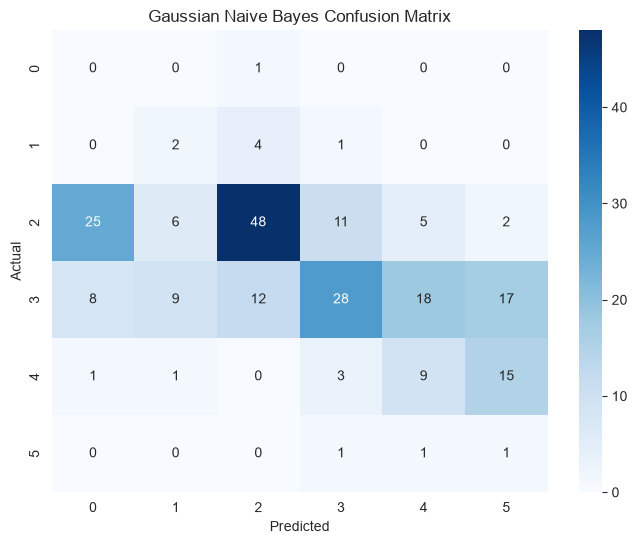

In [30]:
#confusion matrix shows that out of 97 that has a quality of 5 , only 48 of them were accurately predicted
cm = confusion_matrix(y_ts, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gaussian Naive Bayes Confusion Matrix")

plt.show()

In [32]:
#tring again without oversampling this time
gnb = GaussianNB()

gnb.fit(x_tn, y_tn)

y_pred_no_sampling = gnb.predict(x_ts)

print(classification_report(y_ts, y_pred_no_sampling))

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.20      0.14      0.17         7
           5       0.77      0.64      0.70        97
           6       0.59      0.64      0.61        92
           7       0.33      0.38      0.35        29
           8       0.10      0.33      0.15         3

    accuracy                           0.59       229
   macro avg       0.33      0.36      0.33       229
weighted avg       0.61      0.59      0.59       229



C:\Users\ICT012\PycharmProjects\PythonProject3\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ICT012\PycharmProjects\PythonProject3\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ICT012\PycharmProjects\PythonProject3\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

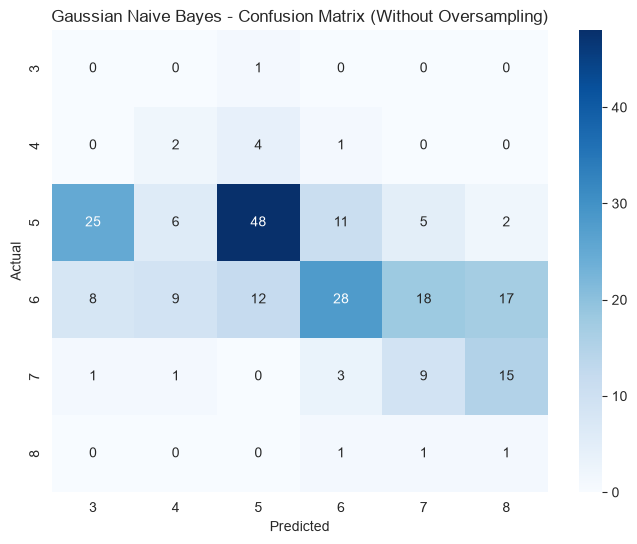

In [33]:
#another confusion matrix after performing without over sampling
cm = confusion_matrix(y_ts, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y_ts.unique()),
    yticklabels=sorted(y_ts.unique())
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Gaussian Naive Bayes - Confusion Matrix (Without Oversampling)")
plt.show()

In [34]:
# for bonus task you asked us to use Generative NB to generate new data , how that works it uses the class (mean , variance) that it learned before to generate new samples

In [35]:
# Number of samples we want to generate
n_samples = 10
generated_data = []

for i in range(n_samples):

    # Choose a random class
    class_index = np.random.randint(len(gnb.classes_))

    # Get the mean and variance for this class
    mean = gnb.theta_[class_index]
    variance = gnb.var_[class_index]

    # Generate a new sample
    sample = np.random.normal( mean, np.sqrt(variance)
    )
    generated_data.append(sample)

# Convert generated samples to DataFrame
generated_df = pd.DataFrame( generated_data, columns=X.columns
)

generated_df.head(10)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,8.926548,0.704856,0.415074,2.232647,0.063682,13.022787,32.230200,0.997091,3.283880,0.745273,11.340945
1,13.049578,0.307791,0.916625,3.559459,0.087146,7.896375,-2.769627,0.995959,3.314635,0.867068,11.098902
2,8.468684,0.239595,0.390586,2.933150,0.073224,9.520415,24.901473,1.000073,3.577224,0.715501,12.497542
3,9.625049,0.458936,0.360248,0.939339,0.018577,19.250405,136.637657,0.994777,3.372285,0.763489,11.202476
4,11.693187,0.732445,0.295759,5.424577,0.104719,6.415669,4.315521,0.999090,3.385891,0.655846,10.073160
5,10.543164,0.627751,-0.003061,2.426451,0.154385,37.694736,32.795699,0.999978,3.277196,0.834657,10.413883
6,8.151038,0.412166,0.229891,1.312723,0.076974,18.584043,31.480969,0.995500,3.341699,0.751387,11.376254
7,6.904663,1.069949,0.588103,7.249474,0.138905,5.925682,3.576738,0.996565,3.631923,0.598886,9.436513
8,8.971405,0.326179,0.387894,1.816386,0.071011,25.610157,105.181187,0.996456,3.334956,0.673250,12.608888
9,9.950467,0.580691,0.059287,2.407373,0.208205,8.371397,56.363446,0.994159,3.321219,0.667589,10.211935


In [36]:
#same as before but i added quality

n_samples = 10
generated_data = []
generated_quality = []

for i in range(n_samples):

    # Choose a random class
    class_index = np.random.randint(len(gnb.classes_))

    # Get the class
    quality = gnb.classes_[class_index]

    # Get mean and variance
    mean = gnb.theta_[class_index]
    variance = gnb.var_[class_index]

    # Generate sample
    sample = np.random.normal( mean, np.sqrt(variance)
    )

    generated_data.append(sample)
    generated_quality.append(quality)

generated_df = pd.DataFrame( generated_data, columns=X.columns
)

generated_df["quality"] = generated_quality

generated_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,6.497206,0.273068,0.223659,2.225391,0.130697,11.446918,18.443678,0.998173,3.481348,0.660008,10.050974,5
1,6.752790,0.290019,0.492774,4.414969,0.124634,7.310084,15.601838,0.996188,3.170343,0.492198,11.532336,7
2,5.065429,0.363179,0.228794,3.667437,0.072588,10.310523,36.951665,0.992825,3.284860,0.672000,10.833358,6
3,13.949303,0.278473,0.156966,6.638460,0.079400,12.270590,5.368468,0.996327,3.190365,0.824991,12.091252,7
4,7.574684,0.444786,0.299032,3.219738,0.060357,18.386174,45.776124,0.995225,3.427895,0.488241,10.738185,6
5,8.847428,1.140816,0.616371,2.511297,0.118325,5.803202,32.147876,0.999844,3.273724,0.595419,10.396765,3
6,7.087749,0.509411,0.392100,3.538668,0.074180,13.766014,84.357384,0.996452,3.411623,0.792430,12.484141,7
7,11.185424,0.375767,0.295477,1.068343,0.087270,7.104299,52.866857,0.997114,3.214380,0.515305,14.202877,8
8,9.164685,0.359567,0.437066,3.871401,0.070271,15.492173,17.857540,0.997514,3.253677,0.769639,11.079052,8
9,9.493840,0.621228,0.266482,1.880043,0.121873,6.873787,20.522145,0.998094,3.746137,0.578950,12.428571,6


In [37]:
# visualising data
generated_df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,8.561854,0.465631,0.340872,3.303575,0.093959,10.876376,32.989358,0.996775,3.345435,0.638918,11.583751,6.300000
std,2.584768,0.261450,0.141546,1.552298,0.026788,4.181268,23.273538,0.001898,0.176171,0.125528,1.244346,1.494434
min,5.065429,0.273068,0.156966,1.068343,0.060357,5.803202,5.368468,0.992825,3.170343,0.488241,10.050974,3.000000
25%,6.836530,0.307406,0.238216,2.296868,0.072986,7.155746,18.004074,0.996223,3.224204,0.531216,10.761979,6.000000
50%,8.211056,0.369473,0.297255,3.379203,0.083335,10.878721,26.335010,0.996783,3.279292,0.627714,11.305694,6.500000
75%,9.411551,0.493255,0.425825,3.820410,0.120986,13.392158,43.570009,0.997949,3.423827,0.745229,12.344241,7.000000
max,13.949303,1.140816,0.616371,6.638460,0.130697,18.386174,84.357384,0.999844,3.746137,0.824991,14.202877,8.000000
